# Start/sit analyzer: who to start to win this week's matchup

Engine: [`analysis/lineup.py`](../analysis/lineup.py), which reads live from ESPN: rosters, injury tags and the matchup
score including today's games. It simulates the rest of the week for both teams and scores every legal lineup of
your players who have a game on the target day by **P(win week)**, using the same random draws for each.
The method is in the script's docstring.

Set `TEAM`, `DATE` and `AVAIL` below and run all cells. All numbers are as of the run, so rerun close to lineup lock
for fresh injury news. The same report in the terminal: `python analysis/lineup.py --team 4 --date 2026-11-18`.

## Answer for Wed Nov 18, 2026 (run the evening of Nov 17, 20,000 sims)

**Start:** PG Immanuel Quickley · SG Donovan Mitchell · SF Naji Marshall · PF Pascal Siakam · C Myles Turner ·
UT Fred VanVleet · UT Cameron Boozer.
**Bench:** Andrew Nembhard, Collin Sexton, Kyle Kuzma, Daniss Jenkins, Ajay Mitchell, Klay Thompson.

| | P(win week) | Expected categories won |
|---|---|---|
| Recommended lineup | **93.3%** | 6.16 |
| As currently set on ESPN (Thompson SF, Jenkins UT) | 92.5% (−0.8 ± 0.1) | 6.14 |
| Start nobody | 56.1% | 4.72 |

- **You lead 8-1** with today's games counted, against H-Tine Astromechs, with 5 days left (Wed-Sun).
  PTS, AST, STL and 3PM are close to locked (85-98%). BLK is close to lost (7%) and REB leans their way (36%).
  The week comes down to **TO, FG% and FT%** (64-71% each): you need to keep one of those or REB.
- **Changes that matter:** take **Daniss Jenkins** out of UT. Never start **Andrew Nembhard** (day-to-day, about −1.0
  point of P(win week)) or **Collin Sexton** (−1.0). Kuzma (FT% z −1.5) also costs a little.
- **Toss-ups:** Marshall, Boozer, VanVleet, Ajay Mitchell and Thompson are within ±0.2 points of each other
  (section 3). Any two of them in the last spots is fine. Turner (+1.2 points, almost all your BLK hope) and
  D. Mitchell (+0.7) matter most.
- **If a starter is ruled out before lock**, put Ajay Mitchell in his spot (section 4 table).
- You have more usable starts left this week than they do (31 vs 28).

Numbers change as news and late games come in. Rerun the notebook, or `python analysis/lineup.py --team 4`,
before the 7:00 PM ET lock.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'analysis'))
import lineup as lu

TEAM, DATE = 4, '2026-11-18'
AVAIL = {}            # e.g. {'Andrew Nembhard': 0.3}: chance a player plays each game
SIMS, SEED = 20000, 7

# chart style: you = blue, opponent = orange, context = gray
ME, OPP, GRAY, INK, INK2, MUTED, GRID, SURF = '#2a78d6', '#eb6834', '#c3c2b7', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#fcfcfb'
DIVERGE = LinearSegmentedColormap.from_list('div', ['#e34948', '#f0efec', '#2a78d6'])
plt.rcParams.update({
    'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF, 'figure.dpi': 110,
    'font.family': 'sans-serif', 'font.size': 10, 'text.color': INK, 'axes.labelcolor': INK2,
    'axes.edgecolor': GRAY, 'axes.linewidth': 0.8, 'xtick.color': MUTED, 'ytick.color': INK2,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID,
    'grid.linewidth': 0.6, 'axes.axisbelow': True, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'legend.frameon': False})
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30)

In [2]:
R = lu.analyze(TEAM, DATE, AVAIL, SIMS, SEED)
lu.report(R)

Ligma Sugma vs H-Tine Astromechs: matchup period 5, days 30-34 (Wed Nov 18 - Sun Nov 22)
score so far (live, through today): 8-1-0
  note: 2 of today's NBA games are not final; their remaining minutes are not simulated
player-games left (rostered, available): you 38, opponent 34; 20000 sims

=== Wed Nov 18 (scoring period 30): your players with a game
           player   pos          game     status  p_play now   PTS  REB  AST  STL  BLK  3PM   TO  FG%   FGA  FT%  FTA    z9 START
Immanuel Quickley PG/SG  19:30 vs WSH     ACTIVE    0.95  SG 17.28 3.70 5.71 1.10 0.10 2.47 1.26 0.42 13.80 0.86 3.63  0.30    PG
    Pascal Siakam    PF  19:00 vs HOU     ACTIVE    0.95  PF 23.22 6.41 4.00 0.96 0.23 1.66 1.85 0.52 16.53 0.74 6.11  0.00    PF
  Andrew Nembhard PG/SG  19:00 vs HOU DAY_TO_DAY    0.60  BE 14.87 2.56 7.03 0.66 0.18 1.85 2.35 0.45 11.63 0.87 2.91 -2.28     -
     Myles Turner     C   19:00 @ MIA     ACTIVE    0.95   C  9.06 5.94 2.31 0.66 1.90 1.68 1.73 0.39  8.23 0.78 1.18 -1.61   

                         starters P(win week)      vs rec. exp cats won    PTS    REB    AST    STL   BLK   FG3M    TOV    FG%    FT%
RECOMMENDED                     7       93.3%                      6.16  95.7%  35.9%  90.9%  84.7%  7.0%  98.1%  63.8%  69.3%  70.7%
best 9-cat (z9) lineup          7       93.3%   -0.0 ± 0.1         6.15  96.3%  26.0%  89.0%  83.8%  7.3%  98.6%  70.3%  70.9%  72.3%
as currently set on ESPN        7       92.5%   -0.8 ± 0.1         6.14  96.1%  33.8%  88.6%  82.1%  7.7%  98.5%  65.4%  68.9%  73.2%
start nobody                    0       56.1%  -37.2 ± 0.3         4.72  42.9%   2.3%  45.0%  55.9%  1.3%  84.2%  93.6%  73.3%  73.2%

=== Projected final totals (mean), recommended lineup
                    PTS      REB      AST     STL     BLK    FG3M     TOV    FG%    FT%
you             636.504  172.186  163.801  38.440  17.143  75.304  66.790  0.473  0.811
opponent        535.802  180.460  136.470  30.476  26.199  53.022  71.138  0.459  0.786
P(you win c

## 1. Where the matchup stands

The score so far includes today's games. The charts show where each category is projected to finish after the
remaining days. Both teams start their best lineup every day after tomorrow, and you start the recommended
lineup tomorrow.

,you,opponent,leader,you (proj.),opponent (proj.),P(you win)
PTS,206.000,132.000,you,636.504,535.802,96%
REB,46.000,38.000,you,172.186,180.460,36%
AST,48.000,35.000,you,163.801,136.470,91%
STL,12.000,5.000,you,38.440,30.476,85%
BLK,4.000,6.000,opponent,17.143,26.199,7%
3PM,27.000,14.000,you,75.304,53.022,98%
TO,13.000,19.000,you,66.790,71.138,64%
FG%,0.507,0.398,you,0.473,0.459,69%
FT%,0.853,0.762,you,0.811,0.786,71%


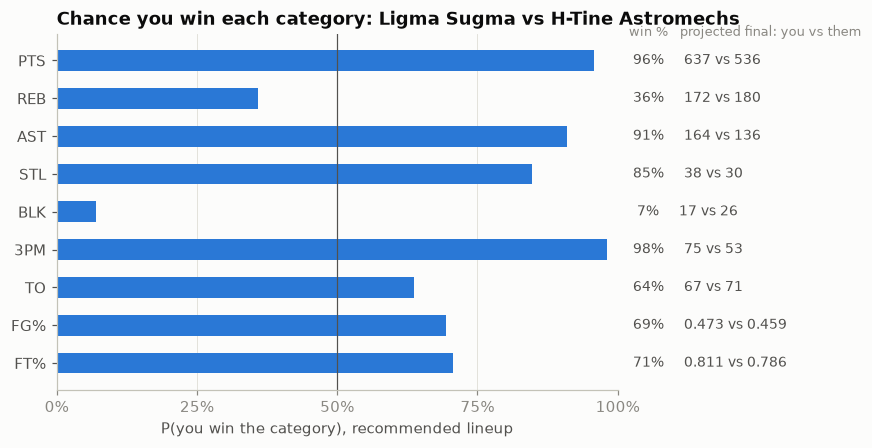

In [3]:
C, best, S = R['cands'], R['best'], R['sims']
rec = R['sims_for'](best['set'])
names = R['names']; me_name, opp_name = names[R['team']], names[R['opp_id']]
cats = [{'FG3M': '3PM', 'TOV': 'TO'}.get(c, c) for c in lu.SIM_CATS]    # ESPN's names
so_far = pd.DataFrame({'you': lu.fmt9(R['base_me']), 'opponent': lu.fmt9(R['base_opp'])}, index=cats)
so_far['leader'] = np.where(lu.compare(R['base_me'], R['base_opp']) > 0, 'you',
                            np.where(lu.compare(R['base_me'], R['base_opp']) < 0, 'opponent', 'tied'))
final = pd.DataFrame({'you (proj.)': lu.fmt9(best['my_mean']), 'opponent (proj.)': lu.fmt9(R['tot_opp'].mean(0)),
                      'P(you win)': best['per_cat']}, index=cats)
display(pd.concat([so_far, final], axis=1).style.format(precision=3).format('{:.0%}', subset=['P(you win)']))

# chance to win each category
fig, ax = plt.subplots(figsize=(8.5, 4.2))
p = best['per_cat'] * 100
y = np.arange(len(cats))[::-1]
ax.barh(y, p, height=0.55, color=ME)
ax.axvline(50, color=INK2, lw=0.8)
ax.set_yticks(y, cats); ax.set_xlim(0, 100); ax.set_xticks([0, 25, 50, 75, 100], ['0%', '25%', '50%', '75%', '100%'])
ax.grid(axis='y', visible=False)
ax.text(102, len(cats) - 0.35, 'win %   projected final: you vs them', fontsize=8.5, color=MUTED, clip_on=False)
for yi, pi, c in zip(y, p, cats):
    yo, oo = final.loc[c, 'you (proj.)'], final.loc[c, 'opponent (proj.)']
    f = (lambda v: f'{v:.3f}') if '%' in c else (lambda v: f'{v:.0f}')
    ax.text(102, yi, f'{pi:>3.0f}%     {f(yo)} vs {f(oo)}', va='center', fontsize=9, color=INK2, clip_on=False)
ax.set_title(f'Chance you win each category: {me_name} vs {opp_name}')
ax.set_xlabel('P(you win the category), recommended lineup')
plt.subplots_adjust(left=0.08, right=0.68); plt.show()

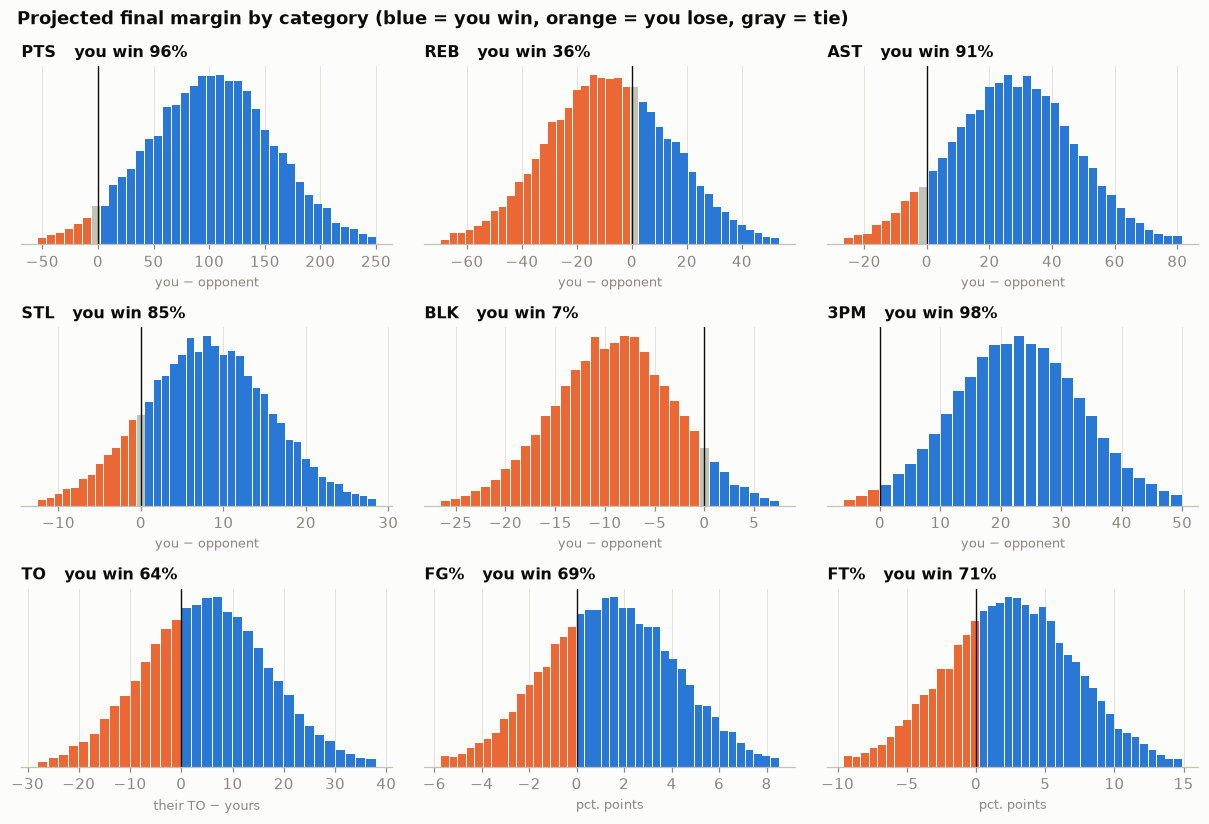

In [4]:
# projected final margin per category (positive = you win; TO is flipped so fewer turnovers is positive)
def margins(tot_me, tot_opp):
    I = lu.I
    out = {}
    for c, k in zip(['PTS', 'REB', 'AST', 'STL', 'BLK', '3PM'], ['PTS', 'REB', 'AST', 'STL', 'BLK', 'FG3M']):
        out[c] = tot_me[:, I[k]] - tot_opp[:, I[k]]
    out['TO'] = tot_opp[:, I['TOV']] - tot_me[:, I['TOV']]
    for c, m, a in (('FG%', 'FGM', 'FGA'), ('FT%', 'FTM', 'FTA')):
        out[c] = 100 * (tot_me[:, I[m]] / np.maximum(tot_me[:, I[a]], 1) - tot_opp[:, I[m]] / np.maximum(tot_opp[:, I[a]], 1))
    return pd.DataFrame(out)

M = margins(rec['tot'], R['tot_opp'])
fig, axes = plt.subplots(3, 3, figsize=(11, 7.6))
for ax, c, pc in zip(axes.flat, M.columns, best['per_cat']):
    v = M[c].values
    lo_, hi_ = np.percentile(v, [0.5, 99.5])
    lo_, hi_ = min(lo_, -abs(hi_) * 0.05), max(hi_, abs(lo_) * 0.05)
    if '%' in c:
        bins = np.linspace(lo_, hi_, 41)
    else:   # whole-number margins: bins centred on integers, so a tie (0) gets its own bar
        step = max(1, int(np.ceil((hi_ - lo_) / 40)))
        bins = np.arange(np.floor(lo_) - step / 2, np.ceil(hi_) + step, step)
    n, edges = np.histogram(v, bins)
    mid = (edges[:-1] + edges[1:]) / 2
    tie = (edges[:-1] < 0) & (edges[1:] > 0) if '%' not in c else np.zeros(len(mid), bool)
    ax.bar(mid, n / len(v) * 100, width=(edges[1] - edges[0]) * 0.9,
           color=np.where(tie, GRAY, np.where(mid > 0, ME, OPP)))
    ax.axvline(0, color=INK, lw=0.9)
    ax.set_title(f'{c}   you win {pc:.0%}', fontsize=10.5)
    ax.set_yticks([]); ax.grid(axis='y', visible=False); ax.spines['left'].set_visible(False)
    ax.set_xlabel('pct. points' if '%' in c else ('their TO − yours' if c == 'TO' else 'you − opponent'), fontsize=8.5, color=MUTED)
fig.suptitle('Projected final margin by category (blue = you win, orange = you lose, gray = tie)', x=0.01, ha='left',
             fontweight='bold', fontsize=12)
plt.tight_layout(); plt.show()

## 2. Which categories decide the week

A category is **pivotal** in a simulation when flipping its result alone would change the week's result.
The share of simulations where it's pivotal shows where tomorrow's choices matter. A category you almost always
win (or lose) is rarely pivotal, and neither is any category in a week that is already a blowout.

,P(you win cat),P(pivotal),lose week because of it
PTS,95.7%,21.0%,1.5%
REB,35.9%,8.4%,5.9%
AST,90.9%,19.4%,2.2%
STL,84.7%,17.1%,2.8%
BLK,7.0%,6.4%,6.1%
3PM,98.1%,21.0%,0.6%
TO,63.8%,13.0%,2.9%
FG%,69.3%,14.0%,4.1%
FT%,70.7%,14.2%,3.9%


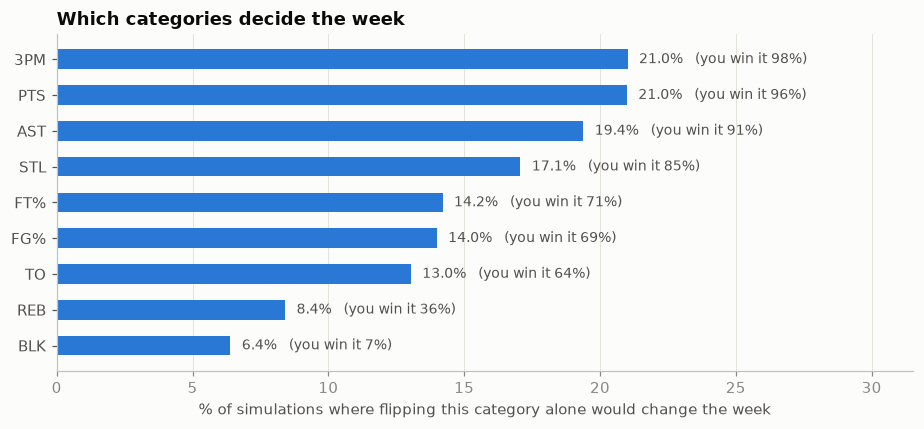

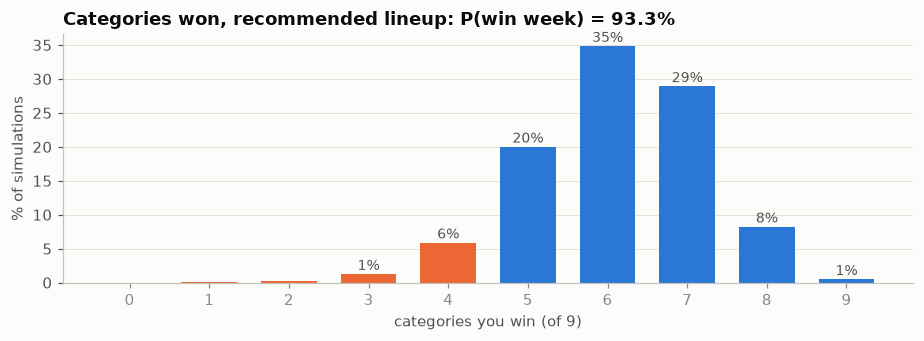

In [5]:
win = rec['win']; r = rec['r']
w, l = (r > 0).sum(1), (r < 0).sum(1)
outcome = lambda w, l: (w > l) + 0.5 * (w == l)
piv = {}
for j, c in enumerate(cats):
    won, lost = r[:, j] > 0, r[:, j] < 0
    flipped = np.where(won, outcome(w - 1, l + 1), np.where(lost, outcome(w + 1, l - 1), outcome(w, l)))
    piv[c] = {'P(you win cat)': best['per_cat'][j], 'P(pivotal)': (np.abs(flipped - outcome(w, l)) > 0).mean(),
              'lose week because of it': ((flipped > outcome(w, l)) & lost).mean()}
piv = pd.DataFrame(piv).T
display(piv.style.format('{:.1%}'))

order = piv['P(pivotal)'].sort_values().index
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.barh(range(len(order)), piv.loc[order, 'P(pivotal)'] * 100, height=0.55, color=ME)
ax.set_yticks(range(len(order)), order); ax.grid(axis='y', visible=False)
xmax = piv['P(pivotal)'].max() * 100
for i, c in enumerate(order):
    ax.text(piv.loc[c, 'P(pivotal)'] * 100 + xmax * 0.02, i,
            f"{piv.loc[c, 'P(pivotal)']:.1%}   (you win it {piv.loc[c, 'P(you win cat)']:.0%})", va='center', fontsize=9, color=INK2)
ax.set_xlim(0, xmax * 1.5)
ax.set_xlabel('% of simulations where flipping this category alone would change the week')
ax.set_title('Which categories decide the week')
plt.tight_layout(); plt.show()

# how many categories you end up winning
nw = (r > 0).sum(1)
fig, ax = plt.subplots(figsize=(8.5, 3.2))
k = np.arange(10); share = np.array([(nw == i).mean() * 100 for i in k])
ax.bar(k, share, width=0.7, color=np.where(k >= 5, ME, OPP))
for i, s in zip(k, share):
    if s >= 0.5: ax.text(i, s + 0.6, f'{s:.0f}%', ha='center', fontsize=9, color=INK2)
ax.set_xticks(k); ax.set_xlabel('categories you win (of 9)'); ax.set_ylabel('% of simulations')
ax.grid(axis='x', visible=False)
ax.set_title(f"Categories won, recommended lineup: P(win week) = {best['p_win']:.1%}")
plt.tight_layout(); plt.show()

## 3. Tomorrow's lineup choices, ranked

These are the top legal lineups by P(win week). Each error bar is ±2 standard errors of that lineup's
difference from the recommended one, paired over the same simulations. A bar that reaches the recommended
lineup's value means the two are statistically tied. Lineups are labeled by how they differ from the
recommended one.

,lineup,P(win week),diff,se,exp cats
0,RECOMMENDED,93.32%,+0.00%,0.00%,6.161
1,+Ajay Mitchell +Thompson −Boozer −Marshall [best 9-cat (z9) lineup],93.30%,-0.02%,0.14%,6.146
2,+Ajay Mitchell −Boozer,93.30%,-0.02%,0.12%,6.146
3,+Ajay Mitchell −VanVleet,93.17%,-0.15%,0.11%,6.178
4,+Ajay Mitchell −Siakam,93.16%,-0.16%,0.12%,6.155
5,+Ajay Mitchell −Quickley,93.05%,-0.26%,0.12%,6.169
6,+Ajay Mitchell +Kuzma −Boozer −Marshall,93.04%,-0.28%,0.14%,6.142
7,+Ajay Mitchell +Thompson −Siakam −Marshall,93.04%,-0.28%,0.14%,6.158
8,+Thompson −Marshall,93.02%,-0.29%,0.11%,6.160
9,+Ajay Mitchell +Jenkins −VanVleet −Boozer,92.97%,-0.34%,0.14%,6.136


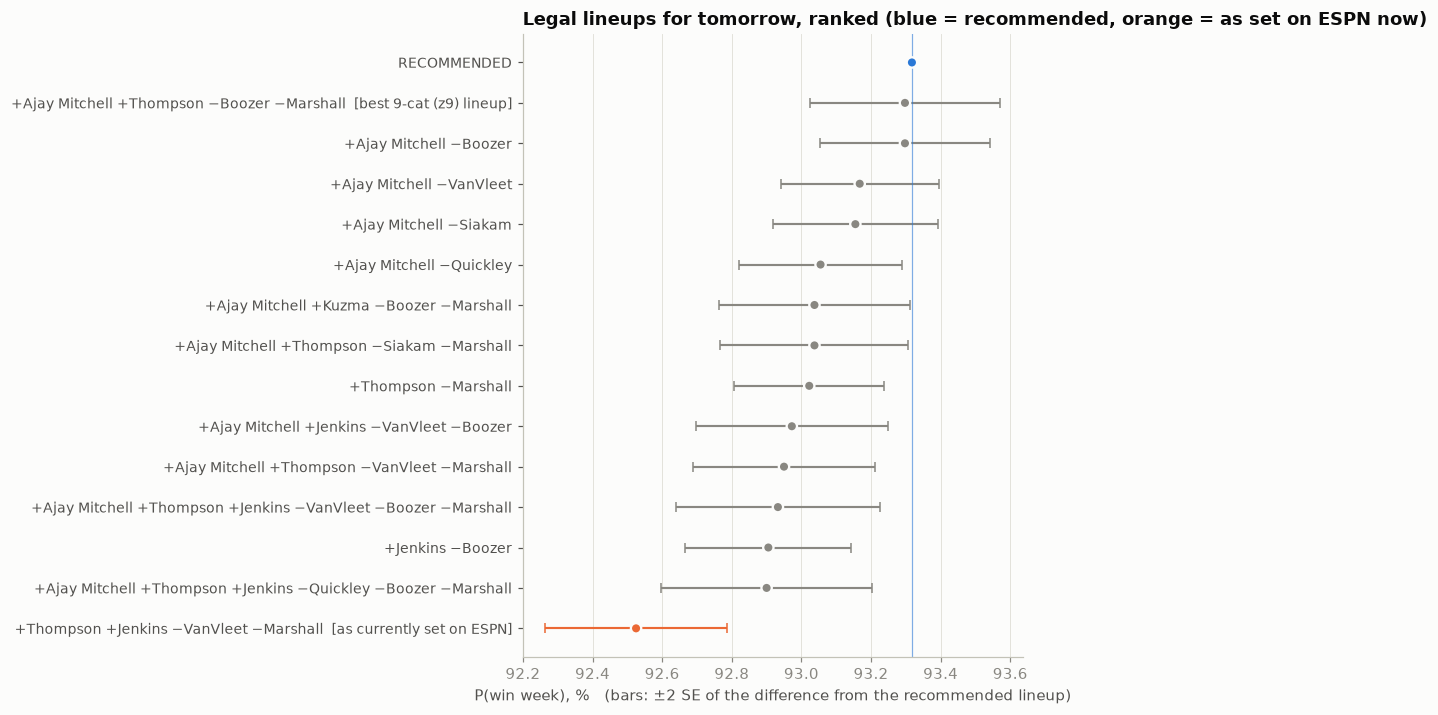

In [6]:
last = lambda j: C[j]['name'].split()[-1] if sum(C[k]['name'].split()[-1] == C[j]['name'].split()[-1] for k in range(len(C))) == 1 else C[j]['name']
bw = rec['win']
def describe(e):
    out = [f'+{last(j)}' for j in e['set'] if j not in best['set']] + [f'−{last(j)}' for j in best['set'] if j not in e['set']]
    return 'RECOMMENDED' if not out else ' '.join(out)

top = sorted(R['evals'], key=lambda e: -e['p_win'])[:14]
extra = [e for k, e in R['compared'].items() if k != 'start nobody' and all(e is not t for t in top)]
rows = []
for e in top + extra:
    d = R['sims_for'](e['set'])['win'] - bw
    tag = [k for k, v in R['compared'].items() if v is e and k != 'RECOMMENDED']
    rows.append({'lineup': describe(e) + (f'  [{tag[0]}]' if tag else ''), 'P(win week)': e['p_win'],
                 'diff': d.mean(), 'se': d.std() / np.sqrt(S), 'exp cats': e['cats'], 'is_rec': e is best,
                 'is_cur': bool(tag) and tag[0] == 'as currently set on ESPN'})
L = pd.DataFrame(rows)
display(L.drop(columns=['is_rec', 'is_cur']).style.format({'P(win week)': '{:.2%}', 'diff': '{:+.2%}', 'se': '{:.2%}', 'exp cats': '{:.3f}'}))

fig, ax = plt.subplots(figsize=(9.5, 0.36 * len(L) + 1.2))
y = np.arange(len(L))[::-1]
col = np.where(L.is_rec, ME, np.where(L.is_cur, OPP, MUTED))
for yi, xv, se, c in zip(y, L['P(win week)'] * 100, L.se * 100, col):
    ax.errorbar(xv, yi, xerr=2 * se, fmt='none', ecolor=c, elinewidth=1.4, capsize=3)
ax.scatter(L['P(win week)'] * 100, y, s=46, c=col, zorder=3, edgecolors=SURF, linewidths=1.5)
ax.axvline(best['p_win'] * 100, color=ME, lw=0.8, alpha=0.6)
ax.set_yticks(y, L.lineup, fontsize=9); ax.grid(axis='y', visible=False)
ax.set_xlabel('P(win week), %   (bars: ±2 SE of the difference from the recommended lineup)')
ax.set_title('Legal lineups for tomorrow, ranked (blue = recommended, orange = as set on ESPN now)')
plt.tight_layout(); plt.show()

## 4. The players: per-game profile and start/bench impact

The heatmap shows each candidate's projected per-game value in each category, as a z-score against the top 156
rostered players. Blue helps and red hurts; FG% and FT% are weighted by attempts. Read it together with
section 2: a red cell matters most in a category that decides the week.

,player,pos,game,status,p_play,now,PTS,REB,AST,STL,BLK,3PM,TO,FG%,FGA,FT%,FTA,z9,START
0,Immanuel Quickley,PG/SG,19:30 vs WSH,ACTIVE,0.95,SG,17.28,3.70,5.71,1.10,0.10,2.47,1.26,0.42,13.80,0.86,3.63,0.30,PG
1,Pascal Siakam,PF,19:00 vs HOU,ACTIVE,0.95,PF,23.22,6.41,4.00,0.96,0.23,1.66,1.85,0.52,16.53,0.74,6.11,0.00,PF
2,Andrew Nembhard,PG/SG,19:00 vs HOU,DAY_TO_DAY,0.60,BE,14.87,2.56,7.03,0.66,0.18,1.85,2.35,0.45,11.63,0.87,2.91,-2.28,-
3,Myles Turner,C,19:00 @ MIA,ACTIVE,0.95,C,9.06,5.94,2.31,0.66,1.90,1.68,1.73,0.39,8.23,0.78,1.18,-1.61,C
4,Donovan Mitchell,PG/SG,19:00 vs MEM,ACTIVE,0.95,PG,25.13,4.79,5.68,1.44,0.38,3.00,2.92,0.49,18.16,0.80,5.57,2.58,SG
5,Fred VanVleet,PG/SG,19:00 @ IND,ACTIVE,0.95,BE,13.71,3.16,5.51,1.14,0.40,2.78,1.20,0.42,11.03,0.82,1.94,0.15,UT
6,Ajay Mitchell,PG/SG,20:00 vs ATL,ACTIVE,0.95,BE,17.52,3.73,3.63,1.33,0.33,1.00,1.55,0.51,13.53,0.85,3.34,0.05,-
7,Cameron Boozer,PF,19:00 @ CLE,ACTIVE,0.95,UT,17.02,8.89,4.63,0.82,0.75,1.45,3.02,0.43,14.16,0.83,4.15,-1.16,UT
8,Klay Thompson,SG/SF,19:00 vs MIL,ACTIVE,0.95,SF,15.05,1.69,1.98,0.27,0.69,3.83,1.02,0.44,11.84,0.95,0.85,-2.03,-
9,Kyle Kuzma,SF/PF,19:00 @ MIA,ACTIVE,0.95,BE,11.82,4.86,2.49,0.90,0.41,1.53,1.86,0.46,9.46,0.62,2.62,-4.69,-


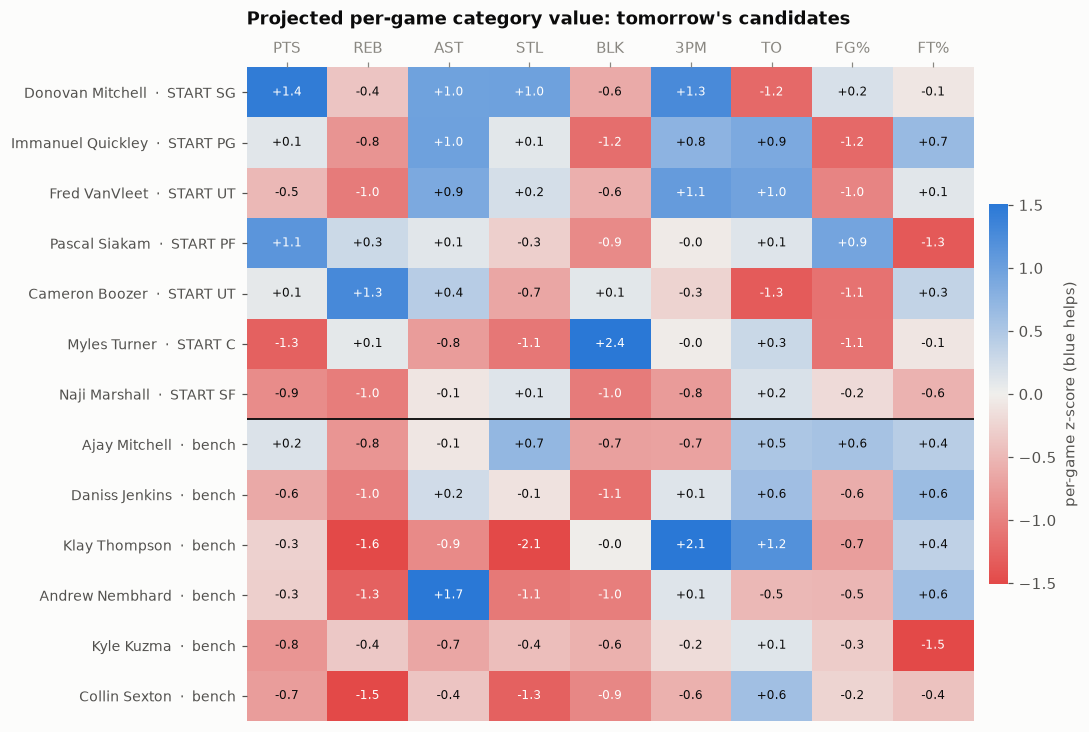

In [7]:
zc = ['z_PTS', 'z_REB', 'z_AST', 'z_STL', 'z_BLK', 'z_FG3M', 'z_TOV', 'z_FG', 'z_FT']
tbl = lu.player_table(R)
Z = pd.DataFrame([{c: p['z'][c] for c in zc} for p in C], index=[p['name'] for p in C])
Z.columns = cats
Z['start'] = tbl['START'].values
Z = Z.assign(z9=[p['z']['z9'] for p in C]).sort_values(['start', 'z9'], key=lambda s: (s == '-') if s.name == 'start' else -s)
display(tbl.round(2))

fig, ax = plt.subplots(figsize=(10, 0.42 * len(Z) + 1.3))
vals = Z[cats].values; lim = np.nanpercentile(np.abs(vals), 95)
im = ax.imshow(vals, cmap=DIVERGE, vmin=-lim, vmax=lim, aspect='auto')
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        ax.text(j, i, f'{vals[i, j]:+.1f}', ha='center', va='center', fontsize=8,
                color=INK if abs(vals[i, j]) < 0.6 * lim else '#ffffff')
ylab = [f"{n}  ·  {'START ' + s if s != '-' else 'bench'}" for n, s in zip(Z.index, Z.start)]
ax.set_yticks(range(len(Z)), ylab, fontsize=9); ax.set_xticks(range(len(cats)), cats)
ax.xaxis.tick_top(); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
nstart = (Z.start != '-').sum(); ax.axhline(nstart - 0.5, color=INK, lw=1.2)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02); cb.set_label('per-game z-score (blue helps)'); cb.outline.set_visible(False)
ax.set_title('Projected per-game category value: tomorrow\'s candidates', pad=28)
plt.tight_layout(); plt.show()

,player,start,impact,se,"if he sits, start"
2,Andrew Nembhard,False,-1.01%,0.14%,
12,Collin Sexton,False,-0.98%,0.14%,
10,Daniss Jenkins,False,-0.34%,0.14%,
9,Kyle Kuzma,False,-0.28%,0.14%,
8,Klay Thompson,False,-0.02%,0.14%,
6,Ajay Mitchell,False,-0.02%,0.14%,
7,Cameron Boozer,True,+0.02%,0.14%,"Ajay Mitchell, Klay Thompson"
11,Naji Marshall,True,+0.02%,0.14%,"Ajay Mitchell, Klay Thompson"
5,Fred VanVleet,True,+0.15%,0.11%,Ajay Mitchell
1,Pascal Siakam,True,+0.16%,0.12%,Ajay Mitchell


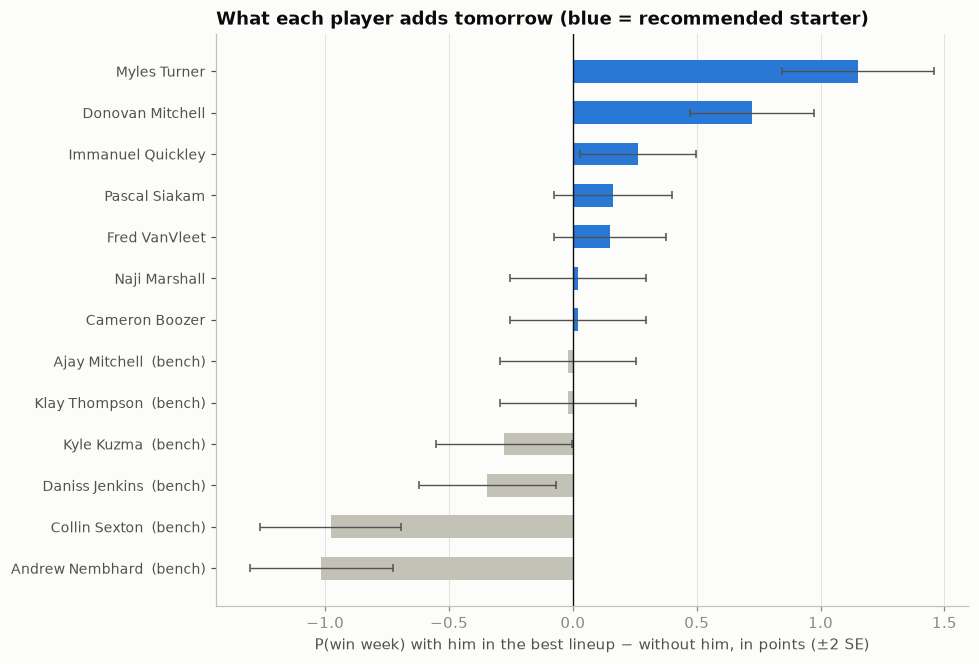

In [8]:
# start/bench impact: best lineup that includes the player vs best lineup without him (paired, ±2 SE)
rows = []
for j, m in enumerate(R['marginal']):
    d = R['sims_for'](m['with']['set'])['win'] - R['sims_for'](m['without']['set'])['win']
    rows.append({'player': m['player'], 'start': m['start'], 'impact': d.mean(), 'se': d.std() / np.sqrt(S),
                 'if he sits, start': ', '.join(m['if_out'])})
Imp = pd.DataFrame(rows).sort_values('impact')
display(Imp.style.format({'impact': '{:+.2%}', 'se': '{:.2%}'}))

fig, ax = plt.subplots(figsize=(9, 0.38 * len(Imp) + 1.2))
y = np.arange(len(Imp))
ax.barh(y, Imp.impact * 100, height=0.55, color=np.where(Imp.start, ME, GRAY))
ax.errorbar(Imp.impact * 100, y, xerr=2 * Imp.se * 100, fmt='none', ecolor=INK2, elinewidth=0.9, capsize=2.5)
ax.axvline(0, color=INK, lw=0.9)
ax.set_yticks(y, [f"{p}{'' if s else '  (bench)'}" for p, s in zip(Imp.player, Imp.start)], fontsize=9)
ax.grid(axis='y', visible=False)
ax.set_xlabel('P(win week) with him in the best lineup − without him, in points (±2 SE)')
ax.set_title('What each player adds tomorrow (blue = recommended starter)')
plt.tight_layout(); plt.show()

## 5. The rest of the week

This counts the players on each roster who have a game each remaining day, excluding OUT and IR players. Only 7
can start, so any count above the line is depth that can't be used that day.

,Wed Nov 18,Thu Nov 19,Fri Nov 20,Sat Nov 21,Sun Nov 22
you,13,5,8,6,6
opponent,11,3,9,5,6
you (usable),7,5,7,6,6
opponent (usable),7,3,7,5,6


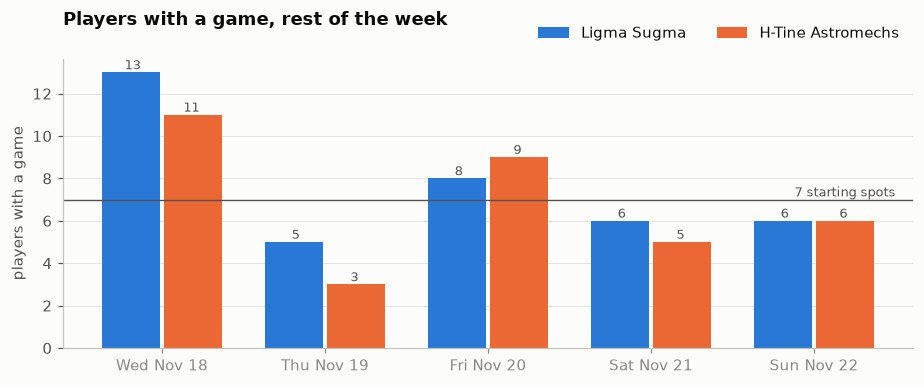

usable starts left: you 31, opponent 28


In [9]:
days = R['sim_days']
cnt = pd.DataFrame({
    'you': [sum(1 for p in R['mine'] if d in R['games'].get(p['pro'], {}) and p['p_play'] > 0) for d in days],
    'opponent': [sum(1 for p in R['theirs'] if d in R['games'].get(p['pro'], {}) and p['p_play'] > 0) for d in days]},
    index=[f"{R['sp_dates'][d]:%a %b %d}" for d in days])
cnt['you (usable)'] = cnt.you.clip(upper=7); cnt['opponent (usable)'] = cnt.opponent.clip(upper=7)
display(cnt.T)

fig, ax = plt.subplots(figsize=(8.5, 3.6))
x = np.arange(len(cnt)); w = 0.36
ax.bar(x - w / 2 - 0.01, cnt.you, w, color=ME, label=me_name)
ax.bar(x + w / 2 + 0.01, cnt.opponent, w, color=OPP, label=opp_name)
ax.axhline(7, color=INK2, lw=0.9); ax.text(len(cnt) - 0.5, 7.15, '7 starting spots', ha='right', fontsize=8.5, color=INK2)
for i in range(len(cnt)):
    ax.text(x[i] - w / 2, cnt.you.iloc[i] + 0.15, cnt.you.iloc[i], ha='center', fontsize=8.5, color=INK2)
    ax.text(x[i] + w / 2, cnt.opponent.iloc[i] + 0.15, cnt.opponent.iloc[i], ha='center', fontsize=8.5, color=INK2)
ax.set_xticks(x, cnt.index); ax.grid(axis='x', visible=False); ax.set_ylabel('players with a game')
ax.legend(loc='upper right', ncol=2, bbox_to_anchor=(1, 1.16))
ax.set_title('Players with a game, rest of the week', pad=22)
plt.tight_layout(); plt.show()
print(f"usable starts left: you {cnt['you (usable)'].sum()}, opponent {cnt['opponent (usable)'].sum()}")